# Логистикалық регрессия мысалы

**Логистикалық регрессия** — объектілерді белгілі бір класқа бөлуге арналған кең таралған **бақыланатын машиналық оқыту алгоритмі**.

Ол кіріс белгілеріне қарап, объектінің белгілі бір класқа жату ықтималдығын есептейді. Бұл алгоритм қарапайым, жылдам және нәтижесін түсіндіру оңай.

- **Бинарлық жіктеуде** қолданылады: мысалы, *иә/жоқ*, *ауру/сау*, *Cammeo/Osmancik*.
- **Көпклассты жіктеуде** де қолданылады: мысалы, объектіні үш немесе одан да көп класқа бөлу.
- Ықтималдықты есептеу үшін **логистикалық немесе сигмоида функциясын** пайдаланады.
- Нәтиже \(0\)-ден \(1\)-ге дейінгі сан болады.

Мысалы, модель күріш дәнінің `Cammeo` түріне жату ықтималдығын `0.85` деп есептесе, бұл:

> Күріштің `Cammeo` класына жату ықтималдығы — 85%.

Әдетте ықтималдық `0.5`-тен жоғары болса — `1` класы, төмен болса — `0` класы таңдалады.



---


## Медициналық өлшемдерге сүйене отырып, ісіктің **қатерлі немесе қатерсіз** екенін болжайтын жіктеу моделін Python тілінде құрайық.

## 1-қадам: Қажетті кітапханаларды импорттау

- **NumPy** — сандармен, математикалық есептеулермен және массивтермен жұмыс істейді.
- **Pandas** — кесте түріндегі деректерді жүктеу, өңдеу және талдау үшін қолданылады.
- **Matplotlib.pyplot** — деректер мен модель нәтижелерін график түрінде көрсетуге көмектеседі.
- **Scikit-learn** — деректерді дайындау, модельді құру, оқыту және бағалау үшін пайдаланылады.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix,precision_score, recall_score,f1_score,roc_curve, roc_auc_score

## **2-қадам: Деректер жиынын жүктеу**

Бұл қадамда Scikit-learn кітапханасынан сүт безі қатерлі ісігі туралы деректер жиыны жүктеледі. Деректер жиыны жіктеу тапсырмасына қажетті ақпараттың барлығын қамтиды:

- **Белгілер матрицасы** — модельге кіріс ретінде берілетін сандық өлшемдер (ісіктің әртүрлі медициналық өлшемдері;).
- **Мақсатты белгілер** — модель болжауы керек кластар (ісіктің қатерлі немесе қатерсіз екенін көрсететін жауабы;).
- **Белгілердің атаулары** — әрбір кіріс белгісінің сипаттамасы (әр өлшемнің атауы;).
- **Метадеректер** — деректер жиыны туралы қосымша ақпарат.

Мұндай құрылым деректерді зерттеуге, алдын ала өңдеуге және модельді оқытуда тікелей пайдалануға ыңғайлы.

**Осы деректерді зерттеп, өңдеп, кейін модельді оқыту үшін қолданамыз.**

In [2]:
data = load_breast_cancer()

## **3-қадам: Деректерді Pandas DataFrame форматына ауыстыру**

Жүктелген деректерді өңдеу және талдау ыңғайлы болуы үшін оларды Pandas кестесіне айналдырамыз. DataFrame деректерді түсінікті түрде көруге, зерттеуге және модельге дайындауға мүмкіндік береді.

- **X** — модельге берілетін кіріс белгілері, яғни ісіктің медициналық өлшемдері.
- **y** — модель болжауы керек нәтиже, яғни ісіктің қатерлі немесе қатерсіз екенін көрсететін класс.

In [3]:
X = pd.DataFrame(data.data, columns=data.feature_names)
y = pd.Series(data.target)

## **4-қадам: Деректерді оқыту және тест жиындарына бөлу**

Бұл қадамда деректер екі бөлікке бөлінеді:

- **75% — оқыту деректері:** модель осы деректер арқылы үйренеді.
- **25% — тест деректері:** оқытылған модельдің жаңа деректерді қаншалықты дұрыс болжайтынын тексеру үшін қолданылады.

In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=29
)

## **5-қадам: Белгілерді масштабтау**

Бұл қадамда барлық сандық белгілер бірдей өлшемге келтіріледі. Себебі кейбір медициналық көрсеткіштер өте үлкен, ал кейбірі өте кіші мәндерден тұруы мүмкін.

Логистикалық регрессия белгілердің көлеміне сезімтал болғандықтан, масштабтау модельдің дұрыс әрі жылдам үйренуіне көмектеседі.

Масштабтау параметрлері тек **оқыту деректері арқылы** есептеледі, содан кейін сол параметрлер тест деректеріне қолданылады. Бұл тест деректері туралы ақпараттың модельге алдын ала өтіп кетуіне, яғни **деректердің ағып кетуіне (data leakage)** жол бермейді.

In [5]:
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

## **6-қадам: Логистикалық регрессия моделін оқыту**

Бұл қадамда модель масштабталған оқыту деректері арқылы үйренеді.

Модель:

- ісіктің әрбір медициналық көрсеткішінің қаншалықты маңызды екенін анықтайды;
- сигмоида функциясы арқылы ісіктің қатерлі немесе қатерсіз болу ықтималдығын есептейді;
- есептелген ықтималдыққа қарай ісікті тиісті класқа жатқызады.

In [6]:
model = LogisticRegression(max_iter=1000)
model.fit(X_train, y_train)

LogisticRegression(max_iter=1000)

## **7-қадам: Болжам жасау**

Бұл кезеңде оқытылған модель бұрын көрмеген тест деректері бойынша болжам жасайды. Алдымен ісіктің әр класқа жату ықтималдығын есептейді, содан кейін әдепкі `0.5` шегі бойынша нәтиже шығарады:

- ықтималдық `0.5` немесе одан жоғары болса — **1, қатерсіз ісік**;
- ықтималдық `0.5`-тен төмен болса — **0, қатерлі ісік**.

In [ ]:
y_pred = model.predict(X_test)
y_pred

array([1, 1, 1, 1, 0, 1, 0, 0, 1, 0, 0, 1, 0, 1, 1, 1, 0, 1, 1, 1, 0, 1,
       1, 1, 0, 0, 0, 1, 0, 0, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 0, 1, 1, 1,
       1, 1, 0, 1, 0, 0, 1, 1, 0, 0, 1, 0, 1, 1, 1, 1, 0, 1, 1, 1, 0, 1,
       1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 1, 1, 0, 1,
       1, 1, 0, 1, 1, 0, 0, 1, 0, 0, 0, 1, 1, 0, 0, 1, 0, 1, 0, 1, 1, 1,
       1, 1, 0, 1, 0, 1, 1, 1, 1, 0, 0, 1, 1, 1, 0, 0, 1, 0, 0, 0, 0, 0,
       1, 0, 1, 0, 0, 1, 1, 0, 1, 1, 1])

## **8-қадам: Модельді бағалау**

Бұл кезеңде модельдің болжамдары қаншалықты дұрыс екенін әртүрлі метрикалар арқылы бағалаймыз. Әр метрика модель жұмысының белгілі бір жағын көрсетеді.

### **Accuracy — жалпы дәлдік**

`Accuracy` модельдің барлық болжамдарының қанша пайызы дұрыс болғанын көрсетеді.

Мысалы, модель 100 ісіктің 95-ін дұрыс анықтаса:

\[
Accuracy=\frac{95}{100}=0.95=95\%
\]

- Модельдің жалпы жұмысын жылдам бағалауға мүмкіндік береді.
- Кластардың саны шамамен бірдей болғанда жақсы көрсеткіш.
- Бір класс екіншісінен әлдеқайда көп болса, нәтиже жаңылыстыруы мүмкін.

Мысалы, 100 науқастың 95-і сау болса, модель барлығын «сау» деп болжау арқылы 95% дәлдік көрсетуі мүмкін. Бірақ ол ауру адамдарды мүлде анықтамайды.

In [ ]:
accuracy = accuracy_score(y_test, y_pred)
print(f"accuracy: {round(accuracy,2)}")

accuracy: 0.99


### **Қателер матрицасы (Confusion Matrix)**

Қателер матрицасы модельдің қай жерде дұрыс, қай жерде қате болжам жасағанын көрсетеді. Ол модельдің болжамын нақты жауаппен салыстырады.

|  | Болжам: қатерлі | Болжам: қатерсіз |
|---|---:|---:|
| **Нақты: қатерлі** | Дұрыс анықтады | Қате қатерсіз деді |
| **Нақты: қатерсіз** | Қате қатерлі деді | Дұрыс анықтады |

Оның көмегімен:

- модельдің нақты қандай қате жібергенін көреміз;
- қатерлі ісікті қатерсіз деп қате анықтаған жағдайларды табамыз;
- қатерсіз ісікті қатерлі деп қате анықтаған жағдайларды көреміз.

Медицинада бұл өте маңызды. Өйткені қатерлі ісікті **қатерсіз деп қате болжау** науқастың емді кеш алуына әкелуі мүмкін. Сондықтан тек жалпы дәлдікке қарау жеткіліксіз.

In [ ]:
cm = confusion_matrix(y_test, y_pred)
cm

array([[52,  1],
       [ 0, 90]])

### **Precision — оң болжамның дәлдігі**

`Precision` модель «оң класс» деп болжаған жағдайлардың қаншасы шынымен оң болғанын көрсетеді.

\[
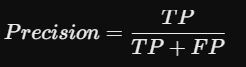
\]

Мысалы, модель 20 жағдайды «қатерлі» деп белгіледі, оның 18-і шынымен қатерлі болса:

\[
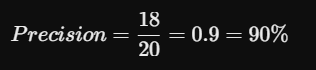
\]

- Жалған оң болжамдарды азайтуға бағытталған.
- Қате оң болжамның салдары қымбат болған жағдайда маңызды.
- Спам хабарламаларын, алаяқтық операцияларды және кейбір медициналық жағдайларды анықтауда қолданылады.

Қарапайым айтқанда:

> Модель «қатерлі» дегенде, оған қаншалықты сенуге болады?

In [ ]:
precision = precision_score(y_test, y_pred)
f"Precision: {round(precision,2)}"

'Precision: 0.99'

### **Recall — оң жағдайларды табу көрсеткіші**

`Recall` нақты оң жағдайлардың қаншасын модель дұрыс тапқанын көрсетеді.

\[
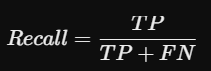
\]

Мысалы, шын мәнінде 20 қатерлі ісік бар, модель оның 18-ін анықтаса:

\[
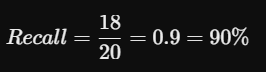
\]

- Анықталмай қалған оң жағдайларды азайтуға бағытталған.
- Қауіпті жағдайды өткізіп алу үлкен зиян келтіретін кезде маңызды.
- Медицинада және қауіпсіздік жүйелерінде жиі қолданылады.

Қарапайым айтқанда:

> Шын мәнінде ауру болған адамдардың қаншасын модель анықтады?

Ескерту: сіздің деректеріңізде `1 = қатерсіз`, `0 = қатерлі`. Сондықтан `recall_score()` әдепкі бойынша қатерсіз ісіктерді есептейді. Қатерлі ісік үшін есептеу керек болса:

```python
recall_score(y_test, y_pred, pos_label=0)
```

In [ ]:
recall = recall_score(y_test, y_pred)
f"Recall: {round(recall,2)}"

'Recall: 1.0'

### **F1 көрсеткіші**

`F1-score` — `Precision` мен `Recall` көрсеткіштерін біріктіріп, модельдің жұмысын бір санмен бағалайтын метрика.

\[
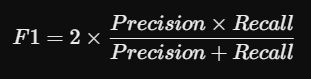
\]

Мысалы:

\[
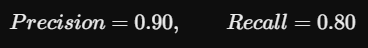
\]

болса:

\[
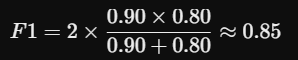
\]

Яғни F1 көрсеткіші шамамен **85%** болады.

- Кластардың саны тең болмаған кезде пайдалы.
- `Precision` жоғары, бірақ `Recall` төмен болса, F1 көрсеткіші де төмендейді.
- Жалған оң және жалған теріс болжамдардың екеуі де маңызды болған жағдайда қолданылады.

Қарапайым айтқанда:

> F1 — модельдің оң болжамдарының дәлдігі мен нақты оң жағдайларды табу қабілеті арасындағы тепе-теңдік.

In [ ]:
f1 = f1_score(y_test, y_pred)
f"f1 score: {round(f1,2)}"

'f1 score: 0.99'

### **ROC-AUC көрсеткіші**

`ROC-AUC` модельдің екі класты бір-бірінен қаншалықты жақсы ажырата алатынын көрсетеді. Ол тек `0.5` шегін емес, әртүрлі шектердегі модель нәтижесін бағалайды.

- `ROC` — әртүрлі шектердегі дұрыс және қате оң болжамдардың арақатынасын көрсететін қисық.
- `AUC` — осы қисықтың астындағы аудан.

| ROC-AUC мәні | Мағынасы |
|---:|---|
| `1.0` | Кластарды мінсіз ажыратады |
| `0.9–1.0` | Өте жақсы |
| `0.8–0.9` | Жақсы |
| `0.7–0.8` | Орташа |
| `0.5` | Кездейсоқ болжаумен бірдей |

Мысалы, `ROC-AUC = 0.97` болса, модель қатерлі және қатерсіз ісіктерді өте жақсы ажыратады.

Қарапайым айтқанда:

> ROC-AUC — модельдің бір класқа жоғары, екінші класқа төмен ықтималдық беру қабілетін бағалайды.

Ол әртүрлі жіктеу модельдерін салыстыруға ыңғайлы: **ROC-AUC мәні жоғары модель кластарды жақсырақ ажыратады.**

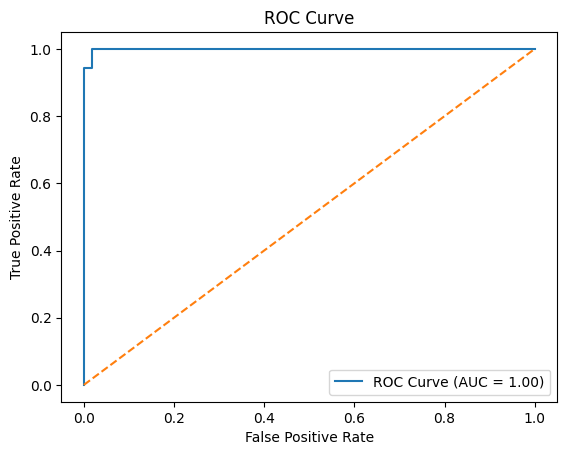

In [ ]:
y_prob = model.predict_proba(X_test)[:, 1]

fpr, tpr, thresholds = roc_curve(y_test, y_prob)

roc_auc = roc_auc_score(y_test, y_prob)

plt.figure()
plt.plot(fpr, tpr, label=f"ROC Curve (AUC = {roc_auc:.2f})")
plt.plot([0, 1], [0, 1], linestyle="--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend()
plt.show()